# AI651 PA2 · Question 2 · Notebook 5 — The final model

Wraps trained models as symmetrised forecasters (eq. 7, no retraining), optionally trains D+B,
and produces **Table 6** and **Figure 6** (with GIFs). Figure 6 reuses exactly the videos chosen
in notebook 3.


In [7]:
# 0) Drive, code and GPU -- run this first in every session
PROJECT = "/content/drive/MyDrive/AI651_PA2"   # data, checkpoints, results, figures live here
UPDATE_CODE = False   # True -> upload pa2_code.zip again (e.g. after you edit a script)

from google.colab import drive
drive.mount("/content/drive")

import os, sys, io, zipfile
CODE_DIR = os.path.join(PROJECT, "code")
os.makedirs(CODE_DIR, exist_ok=True)
if UPDATE_CODE or not os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")):
    from google.colab import files
    print("Upload pa2_code.zip (or the individual pa2/*.py files). "
          "It is stored on Drive, so this is only needed once.")
    for name, blob in files.upload().items():
        if name.endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(blob)).extractall(CODE_DIR)
        elif name.endswith(".py"):
            os.makedirs(os.path.join(CODE_DIR, "pa2"), exist_ok=True)
            clean = name.split(" (")[0].removesuffix(".py") + ".py"   # Colab renames "x (1).py"
            with open(os.path.join(CODE_DIR, "pa2", clean), "wb") as f:
                f.write(blob)
assert os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")), "pa2 package not found on Drive"
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
for m in [m for m in list(sys.modules) if m == "pa2" or m.startswith("pa2.")]:
    del sys.modules[m]                         # always import the version on Drive

import numpy as np
import matplotlib.pyplot as plt
import pa2
from pa2 import config, data, models, train, evaluation, visuals, checks, tables, utils
from pa2.pipeline import Context
from pa2.utils import show_table
%matplotlib inline
print("pa2 version", pa2.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pa2 version 1.0


In [8]:
ctx = Context(PROJECT)
ctx.load_data();   # first run: downloads Moving MNIST (~800 MB) to Drive; later runs load it from there

Device: Tesla T4 (15 GB), torch 2.11.0+cu130
Loading Moving MNIST (downloaded to Drive the first time) ...
{'train': (8000, 20, 1, 64, 64), 'val': (1000, 20, 1, 64, 64), 'test': (1000, 20, 1, 64, 64)}


In [9]:
ctx.load_d_arch()
print("Model D =", ctx.d_arch, config.ARCHS[ctx.d_arch])

Model D = D_dil {'patch': 4, 'hidden': (64, 64), 'kernels': (3, 3), 'dilations': (1, 2)}


In [10]:
SEL_PATH = os.path.join(ctx.paths["results"], "selection.json")
sel = utils.load_json(SEL_PATH, {})        # example videos chosen for the figures (reused later)

## Optional: D+B
Train D+B (speed **and** symmetry augmentation) only if Table 5 supports it, then set
`FINAL = "DB"` to wrap it as your final model. Say which you chose and why in the report.

In [11]:
TRAIN_DB = False
FINAL = "D"            # "D" or "DB": the final model is the symmetrised version of this
if TRAIN_DB or FINAL == "DB":
    for seed in config.SEEDS:
        ctx.train("DB", seed)

## Check: symmetrised models are exactly consistent (up to floating-point error)

In [12]:
for key in ("symB", "symD") + (("symDB",) if (TRAIN_DB or FINAL == "DB") else ()):
    for s in config.SEEDS:
        r = ctx.summary(key, s, ("tr",))
        print(f"{key:6s} seed {s}:  C_M = {r['C_M']:.2e}   C_R = {r['C_R']:.2e}")

symB   seed 0:  C_M = 7.95e-17   C_R = 6.42e-17
symB   seed 1:  C_M = 9.17e-17   C_R = 7.36e-17
symD   seed 0:  C_M = 6.02e-17   C_R = 4.62e-17
symD   seed 1:  C_M = 6.21e-17   C_R = 4.80e-17


## Table 6

In [13]:
keys = ["symB", "symD"] + (["symDB"] if (TRAIN_DB or FINAL == "DB") else [])
train_hw = sorted({h for k in [k[3:] for k in keys] for s in config.SEEDS
                   for h in ctx.train_log(k, s)["hardware"]})
hw = f"training: {'; '.join(train_hw)} | inference: {utils.hardware_string(ctx.device)}"
show_table(tables.table6(ctx, keys, hw))

| Model | E(5) 1× | C_M | E_M | C_R | E_R | E(2) 1× | E(2) 2× | E(2) 3× | Params | Train s/epoch | Inference s |
|---|---|---|---|---|---|---|---|---|---|---|---|
| sym. B | 0.0211 (0.0217, 0.0205) | 8.56e-17 (7.95e-17, 9.17e-17) | 0.0211 (0.0217, 0.0205) | 6.89e-17 (6.42e-17, 7.36e-17) | 0.0211 (0.0217, 0.0205) | 0.0178 (0.0183, 0.0173) | 0.0427 (0.0419, 0.0434) | 0.0460 (0.0448, 0.0472) | 480,784 | 11.5 (11.5, 11.5) | 3.40 (3.39, 3.41) |
| sym. D | 0.0273 (0.0272, 0.0273) | 6.12e-17 (6.02e-17, 6.21e-17) | 0.0273 (0.0272, 0.0273) | 4.71e-17 (4.62e-17, 4.80e-17) | 0.0273 (0.0272, 0.0273) | 0.0246 (0.0246, 0.0246) | 0.0290 (0.0287, 0.0293) | 0.0327 (0.0324, 0.0329) | 480,784 | 16.3 (16.3, 16.3) | 5.57 (5.61, 5.53) |

Test split. Symmetrised models (eq. 7). Training time is that of the underlying learned model. Timings on training: Tesla T4 (15 GB), torch 2.11.0+cu130 | inference: Tesla T4 (15 GB), torch 2.11.0+cu130. Inference includes all 8 transformations, forward passes, inverse transformations and the averaging.

## Figure 6(a) — Figure 3 repeated with the final model (same videos, same transformations)

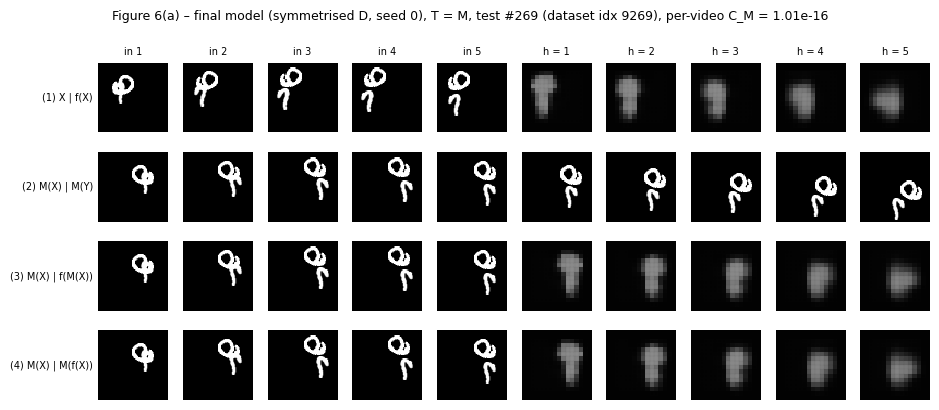

GIF: gifs/fig6a_M_rank1_test269.gif


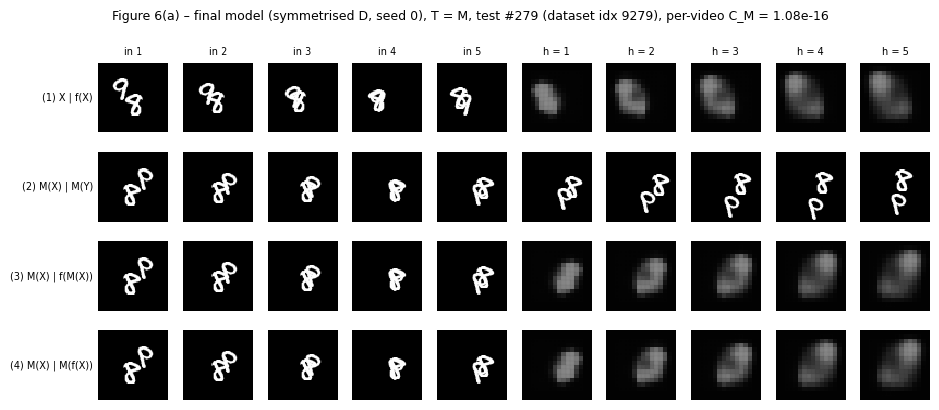

GIF: gifs/fig6a_M_rank2_test279.gif


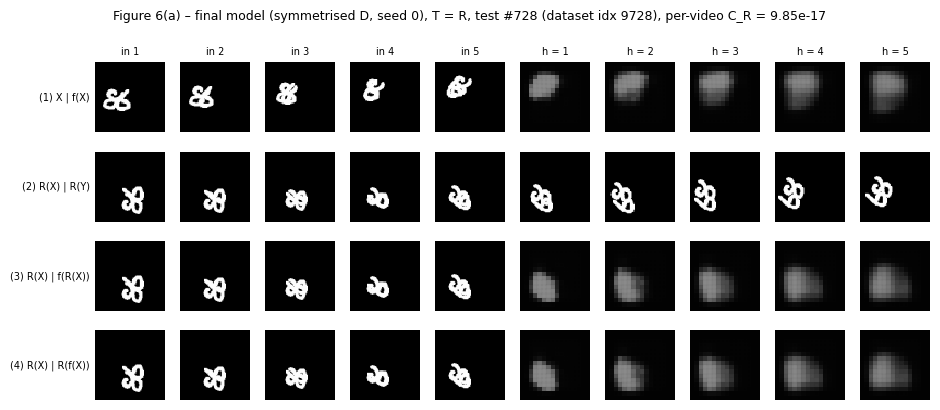

GIF: gifs/fig6a_R_rank1_test728.gif


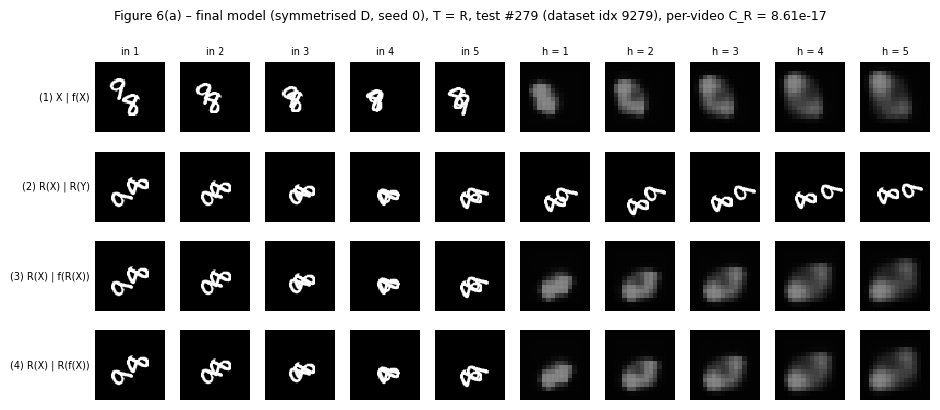

GIF: gifs/fig6a_R_rank2_test279.gif


In [14]:
assert "fig3" in sel and "fig5" in sel, "run notebook 3 first (it chooses the videos)"
final = ctx.model("sym" + FINAL, 0)
final_name = f"final model (symmetrised {'D+B' if FINAL == 'DB' else 'D'}, seed 0)"
tr_F = ctx.metrics("sym" + FINAL, 0, "tr")
for T in ("M", "R"):
    for rank, i in enumerate(sel["fig3"][T], 1):
        png = os.path.join(ctx.paths["figures"], f"fig6a_{T}_rank{rank}_test{i}.png")
        gif = os.path.join(ctx.paths["gifs"], f"fig6a_{T}_rank{rank}_test{i}.gif")
        visuals.figure_consistency_panel(
            final, ctx.test, i, T, ctx.device, png, gif,
            f"Figure 6(a) – {final_name}, T = {T}, {visuals.vid_label(i)}, "
            f"per-video C_{T} = {utils.fmt(tr_F['C_' + T][i])}")
        plt.show()
        print("GIF:", os.path.relpath(gif, PROJECT))

## Figure 6(b) — Figure 5 repeated with the final model (same video)

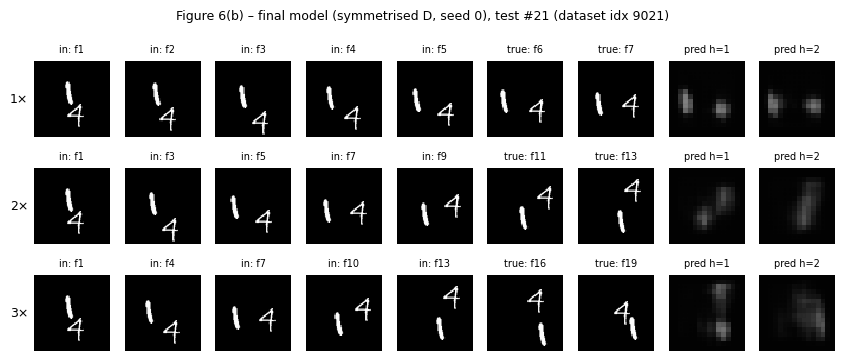

In [15]:
visuals.figure_speeds(final, ctx.test, sel["fig5"], ctx.device,
                      os.path.join(ctx.paths["figures"], "fig6b_speeds_final.png"),
                      f"Figure 6(b) – {final_name}, {visuals.vid_label(sel['fig5'])}")
plt.show()

## Export for the report and the GitHub repository
Zips `figures/`, `gifs/`, `tables/` and `results/` (plus the code) without checkpoints or data.

In [16]:
import shutil
out = "/content/pa2_outputs"
shutil.rmtree(out, ignore_errors=True)
for d in ("figures", "gifs", "tables", "results"):
    shutil.copytree(os.path.join(PROJECT, d), os.path.join(out, d))
shutil.copytree(os.path.join(CODE_DIR, "pa2"), os.path.join(out, "pa2"),
                ignore=shutil.ignore_patterns("__pycache__"))
zip_path = shutil.make_archive("/content/pa2_outputs", "zip", out)
from google.colab import files
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>